# Modèle SVM (Support Vector Machine)

Ce notebook contient l'implémentation et l'évaluation du modèle SVM pour prédire l'attrition des employés.

Le SVM (Support Vector Machine) est un algorithme de classification supervisée capable de séparer des classes à l’aide d’un hyperplan optimal. Dans ce projet, il permet de prédire si un employé risque de quitter l’entreprise (**Attrition = 1**) ou non (**Attrition = 0**) à partir de variables RH préparées.

## Rappel théorique sur le Support Vector Machine (SVM)

Les Support Vector Machines (SVM) sont des modèles d’apprentissage supervisé utilisés principalement pour la classification, mais aussi dans certains cas pour la régression. Leur objectif est de trouver une frontière de décision (hyperplan) qui sépare au mieux les classes dans l’espace des caractéristiques.

L’idée centrale du SVM est de choisir l’hyperplan qui **maximise la marge de séparation**, c’est à dire la distance entre l’hyperplan et les points les plus proches de chaque classe. Ces points critiques sont appelés **vecteurs de support**.

Dans un problème de classification binaire, un hyperplan peut s’écrire sous la forme :

$$
\beta_0 + \beta_1 x_1 + \beta_2 x_2 + \ldots + \beta_n x_n = 0
$$

Le SVM cherche à maximiser la marge, ce qui revient à résoudre un problème d’optimisation visant à minimiser la norme des coefficients :

$$
\min \ \frac{1}{2}\|\beta\|^2
$$

Sous la contrainte de bonne séparation des données :

$$
y^{(i)} \left(\beta_0 + \beta_1 x_1^{(i)} + \beta_2 x_2^{(i)} + \ldots + \beta_n x_n^{(i)}\right) \geq 1
$$

Lorsque les données ne sont pas parfaitement séparables, on utilise une version à **marge souple (soft margin)**, qui autorise certaines erreurs de classification à l’aide de variables de relâchement $\xi_i$ :

$$
\min \ \frac{1}{2}\|\beta\|^2 + C \sum_{i=1}^{m}\xi_i
$$

Sous les contraintes :

$$
y^{(i)} \left(\beta_0 + \beta_1 x_1^{(i)} + \beta_2 x_2^{(i)} + \ldots + \beta_n x_n^{(i)}\right) \geq 1 - \xi_i
$$

$$
\xi_i \geq 0
$$

Le paramètre $C$ contrôle le compromis entre une grande marge et la pénalisation des erreurs de classification.

Pour traiter des relations non linéaires, le SVM peut utiliser des **noyaux (kernels)** qui projettent les données dans un espace de dimension plus élevée. Parmi les noyaux les plus courants, on trouve les noyaux linéaire, polynomial, RBF (radial) et sigmoïde.

Dans ce projet, le SVM est utilisé comme modèle de classification pour comparer ses performances à celles d’autres algorithmes sur la prédiction de l’attrition.

## 1. Importation des bibliothèques

Cette étape permet d’importer les bibliothèques nécessaires pour manipuler les données, entraîner le modèle SVM, évaluer ses performances et sauvegarder les résultats.

In [ ]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.model_selection import train_test_split
from sklearn.svm import SVC
from sklearn.metrics import confusion_matrix, classification_report, roc_auc_score, roc_curve
import pickle

## 2. Chargement des données préparées

On charge le jeu de données prétraité, puis on sépare les variables explicatives (`X`) et la variable cible (`y`).

In [2]:
# Charger les données préparées
data = pd.read_csv('Data/prepared_data.csv')

# Séparer les caractéristiques et la cible
X = data.drop(columns=["Attrition", "EmployeeID"])
y = data['Attrition']

print(f"Shape des features: {X.shape}")
print(f"Shape de la cible: {y.shape}")
print(f"\nDistribution de la cible:\n{y.value_counts()}")

Shape des features: (4410, 45)
Shape de la cible: (4410,)

Distribution de la cible:
Attrition
0    3699
1     711
Name: count, dtype: int64


**Explication :**

La colonne `Attrition` correspond à la variable cible à prédire.  
La colonne `EmployeeID` est supprimée car c’est un identifiant unique, sans utilité prédictive.

L’affichage de la distribution de la cible permet de vérifier si les classes sont équilibrées ou non, ce qui est important pour l’interprétation des résultats.

## 3. Séparation des données

Les données sont divisées en un ensemble d’entraînement et un ensemble de test afin d’évaluer le modèle sur des données qu’il n’a jamais vues.

In [3]:
# Séparation train/test (70/30)
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.3, random_state=42)

print(f"Taille ensemble d'entraînement: {X_train.shape[0]}")
print(f"Taille ensemble de test: {X_test.shape[0]}")

Taille ensemble d'entraînement: 3087
Taille ensemble de test: 1323


**Explication :**

L’ensemble d’entraînement (70 %) est utilisé pour apprendre les paramètres du modèle.  
L’ensemble de test (30 %) est utilisé pour mesurer la capacité de généralisation du modèle.

Le paramètre `random_state=42` garantit la reproductibilité de la séparation.

## 4. Entraînement du modèle SVM

Le Support Vector Machine (SVM) est un algorithme de classification supervisée qui cherche à séparer les différentes classes de données par un hyperplan optimal, maximisant la marge entre les points de chaque classe. Il est particulièrement efficace pour des problèmes de classification non linéaire grâce à l'utilisation de noyaux (kernel).

In [4]:
# Initialisation et entraînement du modèle
svm = SVC(probability=True, random_state=42)
svm.fit(X_train, y_train)

print("Modèle entraîné avec succès!")

Modèle entraîné avec succès!


**Explication :**

`SVC` est l’implémentation du SVM de classification dans `scikit-learn`.  
Le paramètre `probability=True` active le calcul des probabilités, ce qui est nécessaire pour calculer l’AUC-ROC et tracer la courbe ROC.  
`random_state=42` permet d’obtenir des résultats reproductibles.

L’appel à `fit(X_train, y_train)` lance l’apprentissage du modèle sur les données d’entraînement.

## 5. Prédictions

Une fois le modèle entraîné, on génère des prédictions sur l’ensemble de test, à la fois sous forme de classes et de probabilités.

In [5]:
# Prédictions sur l'ensemble de test
y_pred = svm.predict(X_test)
y_proba = svm.predict_proba(X_test)[:, 1]

print("Prédictions effectuées!")

Prédictions effectuées!


**Explication :**

`predict()` retourne la classe prédite (0 ou 1).  
`predict_proba()` retourne la probabilité associée à chaque classe.

Ici, `[:, 1]` permet de récupérer la probabilité de la classe positive (`Attrition = 1`), utile pour le calcul de l’AUC et la courbe ROC.

## 6. Évaluation du modèle

L’évaluation repose sur plusieurs métriques complémentaires afin d’analyser les performances du modèle sous différents angles.

### 6.1 Matrice de confusion

La matrice de confusion compare les classes réelles et les classes prédites, et permet d’identifier les bonnes et mauvaises classifications.

Matrice de Confusion (SVM) :
 [[1108    7]
 [ 109   99]]


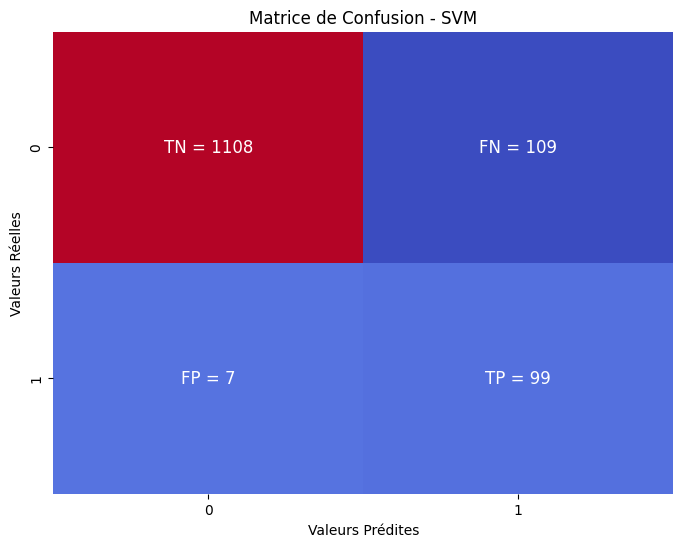

In [ ]:
# Matrice de confusion
conf_matrix = confusion_matrix(y_test, y_pred)
print("Matrice de Confusion (SVM) :\n", conf_matrix)

# Visualisation
plt.figure(figsize=(8, 6))
sns.heatmap(conf_matrix, annot=False, fmt="d", cmap="coolwarm", cbar=False)

# Calcul des valeurs TP, TN, FP, FN
TN, FP, FN, TP = conf_matrix.ravel()

# Ajout des valeurs sur le graphique
plt.text(0.5, 0.5, f'TN = {TN}', ha='center', va='center', color='white', fontsize=12)
plt.text(0.5, 1.5, f'FP = {FP}', ha='center', va='center', color='white', fontsize=12)
plt.text(1.5, 0.5, f'FN = {FN}', ha='center', va='center', color='white', fontsize=12)
plt.text(1.5, 1.5, f'TP = {TP}', ha='center', va='center', color='white', fontsize=12)
plt.title("Matrice de Confusion - SVM")
plt.ylabel('Valeurs Réelles')
plt.xlabel('Valeurs Prédites')
plt.show()

**Explication :**

**TN (True Negatives)** : employés correctement prédits comme non-partants  
**TP (True Positives)** : employés correctement prédits comme partants  
**FP (False Positives)** : employés prédits comme partants alors qu’ils restent  
**FN (False Negatives)** : employés prédits comme non-partants alors qu’ils quittent réellement l’entreprise

Dans un contexte RH, les **FN** sont souvent critiques car ils correspondent à des départs non anticipés.

### 6.2 Rapport de classification

Le rapport de classification fournit des métriques détaillées par classe, comme la précision, le rappel et le F1-score.

In [ ]:
# Rapport de classification
class_report = classification_report(y_test, y_pred)
print("Rapport de Classification (SVM) :\n", class_report)

Rapport de Classification (SVM) :
               precision    recall  f1-score   support

           0       0.91      0.99      0.95      1115
           1       0.93      0.48      0.63       208

    accuracy                           0.91      1323
   macro avg       0.92      0.73      0.79      1323
weighted avg       0.91      0.91      0.90      1323



**Explication :**

**Précision (Precision)** : parmi les prédictions positives, proportion de celles qui sont correctes.  
**Rappel (Recall)** : parmi les cas réellement positifs, proportion détectée par le modèle.  
**F1-score** : compromis entre précision et rappel.  
**Support** : nombre d’observations de chaque classe.

Pour l’attrition, le rappel de la classe positive est particulièrement important si l’objectif est d’anticiper les départs.

### 6.3 Score AUC-ROC

Le score AUC-ROC mesure la capacité du modèle à distinguer les deux classes sur l’ensemble des seuils possibles.

In [ ]:
# AUC-ROC
roc_auc = roc_auc_score(y_test, y_proba)
print(f"AUC-ROC (SVM) : {roc_auc:.4f}")

AUC-ROC (SVM) : 0.9225


**Explication :**

L’AUC varie entre 0 et 1.

Une valeur proche de **0.5** indique un modèle peu performant (proche du hasard).  
Une valeur plus élevée indique une meilleure capacité de discrimination entre employés partants et non-partants.

### 6.4 Courbe ROC

La courbe ROC permet de visualiser la performance du modèle en fonction de différents seuils de décision.

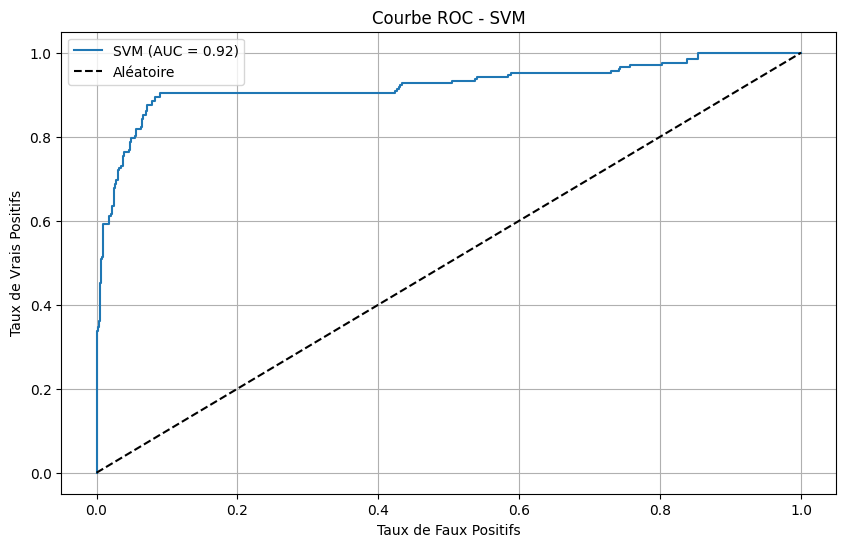

In [ ]:
# Courbe ROC
fpr, tpr, thresholds = roc_curve(y_test, y_proba)

plt.figure(figsize=(10, 6))
plt.plot(fpr, tpr, label=f"SVM (AUC = {roc_auc:.2f})")
plt.plot([0, 1], [0, 1], 'k--', label="Aléatoire")
plt.xlabel("Taux de Faux Positifs")
plt.ylabel("Taux de Vrais Positifs")
plt.title("Courbe ROC - SVM")
plt.legend()
plt.grid(True)
plt.show()

**Explication :**

La courbe ROC met en relation le **taux de faux positifs (FPR)** et le **taux de vrais positifs (TPR)**.

Plus la courbe est proche du coin supérieur gauche, meilleure est la performance du modèle.  
La diagonale représente un classifieur aléatoire.

## 7. Sauvegarde du modèle et des résultats

Cette étape permet de conserver le modèle entraîné et les résultats d’évaluation pour les réutiliser plus tard, notamment dans une comparaison avec d’autres algorithmes.

In [ ]:
# Sauvegarde du modèle
with open('Data/svm_model.pkl', 'wb') as f:
    pickle.dump(svm, f)

# Sauvegarde des résultats
results = {
    'model_name': 'SVM',
    'predictions': y_pred,
    'probabilities': y_proba,
    'auc_roc': roc_auc,
    'confusion_matrix': conf_matrix
}

with open('Data/svm_results.pkl', 'wb') as f:
    pickle.dump(results, f)

print("Modèle et résultats sauvegardés!")

Modèle et résultats sauvegardés!


**Explication :**

La sauvegarde du modèle évite de le réentraîner à chaque fois.  
La sauvegarde des résultats permet de centraliser les performances et de les comparer facilement avec d’autres modèles.

## Résumé

Ce notebook a permis de :

1. Charger les données préparées
2. Entraîner un modèle SVM
3. Générer des prédictions (classes et probabilités)
4. Évaluer les performances avec plusieurs métriques (matrice de confusion, rapport de classification, AUC-ROC, courbe ROC)
5. Sauvegarder le modèle et les résultats pour une comparaison ultérieure

Le SVM constitue un modèle puissant pour la classification, particulièrement pertinent lorsque la séparation entre classes est complexe. Ses performances dépendent toutefois du choix des hyperparamètres et du noyau utilisé.